In [1]:
from wpp import cache, data, db
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
with db.get_con() as con:
    pois_dim = cache.cached_parquet(
        "pois",
        lambda: data.load_pois(con),
    )
    poi_visits = cache.cached_parquet(
        "static_poi_segregation",
        lambda: data.load_static_poi_segregation(con),
    ).with_columns(pl.col("TOTAL_VISITORS").cast(pl.Float64))
    poi_visits_weekly = cache.cached_parquet(
        "weekly_poi_segregation",
        lambda: data.load_weekly_poi_segregation(con),
    )

    cbg_visits = cache.cached_parquet(
        "static_cbg_segregation",
        lambda: data.load_static_cbg_segregation(con),
    )
    cbg_visits_weekly = cache.cached_parquet(
        "weekly_cbg_segregation",
        lambda: data.load_weekly_cbg_segregation(con),
    )

In [3]:
pois_weekly = pois_dim.join(poi_visits_weekly, on="ID_STORE")
pois_weekly.head()

CBSA_NAME,ID_STORE,POI_GEOID,CBSAFP,BRAND,LOCATION_NAME,STREET_ADDRESS,CITY,REGION,ISO_COUNTRY_CODE,NAICS_CODE,TOP_CATEGORY,SUB_CATEGORY,OPEN_DATE,CLOSE_DATE,LONGITUDE,LATITUDE,GEOM,CELL_ID,VISITORS,CATEGORY,NAICS_TITLE,CBSA_NAME_FULL,DATE_RANGE_START,DATE_RANGE_END,AVG_TMEAN,AVG_TMIN,AVG_TMAX,NUM_TEMPERATURE_DAYS,TOTAL_VISITORS_1,TOTAL_VISITORS_2,TOTAL_VISITORS_3,TOTAL_VISITORS_4,AVG_DIST_1,AVG_DIST_2,AVG_DIST_3,AVG_DIST_4,NUM_HOME_GROUPS_1,NUM_HOME_GROUPS_2,NUM_HOME_GROUPS_3,NUM_HOME_GROUPS_4,TOTAL_VISITORS,TAU_1,TAU_2,TAU_3,TAU_4,SEGREGATION,AVG_DIST,NUM_HOME_GROUPS
str,str,str,str,str,str,str,str,str,str,str,str,str,date,date,f64,f64,ext[geoarrow.wkb],i32,"decimal[38,0]",str,str,str,datetime[μs],datetime[μs],f64,f64,f64,i64,"decimal[38,0]","decimal[38,0]","decimal[38,0]","decimal[38,0]",f64,f64,f64,f64,i64,i64,i64,i64,"decimal[38,0]",f64,f64,f64,f64,f64,f64,i64
"""New York""","""10000071""","""360471132001""","""35620""","""General Automotive Repair""","""General Automotive Repair""","""723 Van Sinderen Ave""","""Brooklyn""","""NY""","""US""","""811111""","""Automotive Repair and Maintena…","""General Automotive Repair """,1970-01-01,2038-01-01,-73.898933,40.65873,"b""\x01\x01\x00\x00\x00\x0e\x92\xf4\x1f\x88yR\xc0\x1etd@QTD@""",211253,867324,"""Other""","""General Automotive Repair ""","""New York-Newark-Jersey City, N…",2017-01-02 00:00:00,2017-01-08 00:00:00,null,null,null,0,1609,null,null,null,496.412162,null,null,null,3,0,0,0,1609,1.0,null,null,null,0.5,496.412162,3
"""New York""","""10000071""","""360471132001""","""35620""","""General Automotive Repair""","""General Automotive Repair""","""723 Van Sinderen Ave""","""Brooklyn""","""NY""","""US""","""811111""","""Automotive Repair and Maintena…","""General Automotive Repair """,1970-01-01,2038-01-01,-73.898933,40.65873,"b""\x01\x01\x00\x00\x00\x0e\x92\xf4\x1f\x88yR\xc0\x1etd@QTD@""",211253,867324,"""Other""","""General Automotive Repair ""","""New York-Newark-Jersey City, N…",2017-01-09 00:00:00,2017-01-15 00:00:00,null,null,null,0,639,214,null,null,270.887957,1659.210597,null,null,3,1,0,0,853,0.749121,0.250879,null,null,0.333333,619.189299,4
"""New York""","""10000071""","""360471132001""","""35620""","""General Automotive Repair""","""General Automotive Repair""","""723 Van Sinderen Ave""","""Brooklyn""","""NY""","""US""","""811111""","""Automotive Repair and Maintena…","""General Automotive Repair """,1970-01-01,2038-01-01,-73.898933,40.65873,"b""\x01\x01\x00\x00\x00\x0e\x92\xf4\x1f\x88yR\xc0\x1etd@QTD@""",211253,867324,"""Other""","""General Automotive Repair ""","""New York-Newark-Jersey City, N…",2017-01-16 00:00:00,2017-01-22 00:00:00,null,null,null,0,1183,430,null,null,584.148199,2402.759141,null,null,4,2,0,0,1613,0.733416,0.266584,null,null,0.333333,1068.960788,6
"""New York""","""10000071""","""360471132001""","""35620""","""General Automotive Repair""","""General Automotive Repair""","""723 Van Sinderen Ave""","""Brooklyn""","""NY""","""US""","""811111""","""Automotive Repair and Maintena…","""General Automotive Repair """,1970-01-01,2038-01-01,-73.898933,40.65873,"b""\x01\x01\x00\x00\x00\x0e\x92\xf4\x1f\x88yR\xc0\x1etd@QTD@""",211253,867324,"""Other""","""General Automotive Repair ""","""New York-Newark-Jersey City, N…",2017-01-23 00:00:00,2017-01-29 00:00:00,null,null,null,0,1031,518,null,null,496.842152,2726.850299,null,null,2,2,0,0,1549,0.665591,0.334409,null,null,0.333333,1242.577607,4
"""New York""","""10000071""","""360471132001""","""35620""","""General Automotive Repair""","""General Automotive Repair""","""723 Van Sinderen Ave""","""Brooklyn""","""NY""","""US""","""811111""","""Automotive Repair and Maintena…","""General Automotive Repair """,1970-01-01,2038-01-01,-73.898933,40.65873,"b""\x01\x01\x00\x00\x00\x0e\x92\xf4\x1f\x88yR\xc0\x1etd@QTD@""",211253,867324,"""Other""","""General Automotive Repair ""","""New York-Newark-Jersey City, N…",2017-01-30 00:00:00,2017-02-05 00:00:00,null,null,null,0,958,192,null,null,897.877438,683.185803,null,null,4,

In [4]:
def plot(agg, label, axes):
    plots = [
        ("NUM_POIS", "POIs"),
        ("TOTAL_VISITORS", "Total visitors"),
        ("MEDIAN_VISITORS", "Median visitors"),
        ("MEAN_DIST", "Mean distance"),
        ("MEAN_SEGREGATION", "Mean segregation"),
        ("W_MEAN_SEGREGATION", "Weighted mean segregation"),
        ("MEAN_NUM_HOME_GROUPS", "Mean distinct homes"),
        ("MEDIAN_NUM_HOME_GROUPS", "Median distinct homes", ("Q25_NUM_HOME_GROUPS", "Q75_NUM_HOME_GROUPS")),
    ]

    flat = axes.flatten()
    for ax, plot in zip(flat, plots):
        assert len(plot) in (2, 3)
        column, title, *rest = plot
        err = rest[0] if rest else None

        x = agg["DATE_RANGE_START"]
        ax.plot(
            x,
            agg[column],
            label=label
        )
        ax.set_title(title)
        ax.grid(alpha=0.15)

        # if err:
        #     ax.fill_between(x, agg[err[0]], agg[err[1]], color="C0", alpha=0.2, linewidth=0)

    for ax in list(axes.flat)[len(plots):]:
        ax.set_visible(False)
        
    sns.despine(fig=fig)

In [5]:
filter_expressions = [
    ("All", pl.lit(True)),
    (r"#HOMES $\geq 10$", pl.col("NUM_HOME_GROUPS") >= 10),
    (r"VISITORS $\geq 1000$", pl.col("TOTAL_VISITORS") >= 1000),
    (r"#HOMES $\geq 10$ & VISITORS $\geq 1000$", (pl.col("NUM_HOME_GROUPS") >= 10, pl.col("TOTAL_VISITORS") >= 1000)),
    (r"$\sum_{poi}$#HOMES $\geq 10 \cdot 52$", pl.col("NUM_HOME_GROUPS").sum().over("ID_STORE") >= 10 * 52),
    (r"$\sum_{poi}$#HOMES $\geq 40 \cdot 52$", pl.col("NUM_HOME_GROUPS").sum().over("ID_STORE") >= 100 * 52),
]

Text(0.5, 0.98, 'MIAMI POI summary')

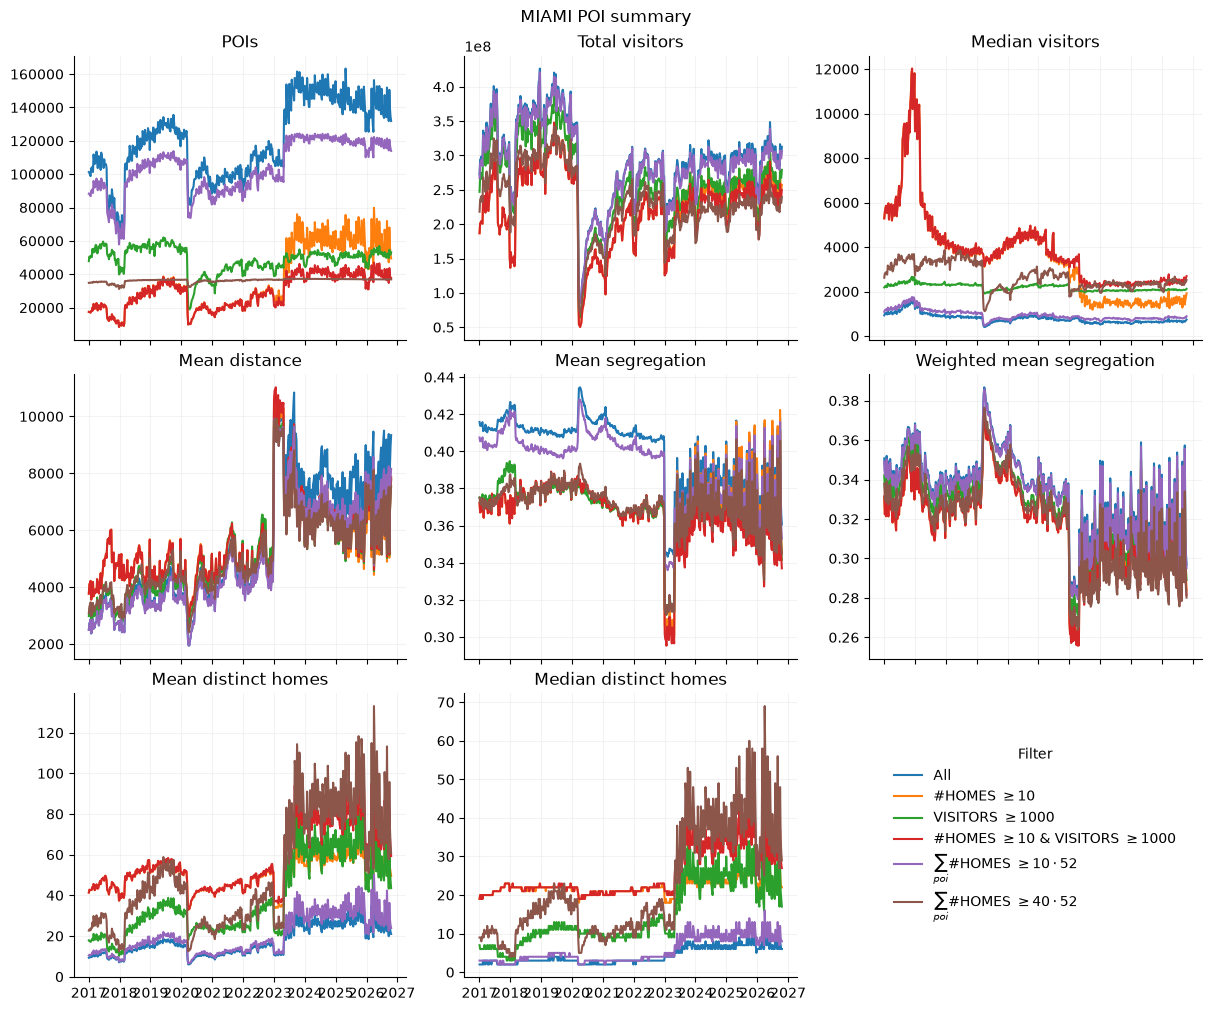

In [6]:
fig, axes = plt.subplots(
    3,
    3,
    figsize=(12, 10),
    sharex=True,
    constrained_layout=True,
)

for label, f in filter_expressions:
    agg = (
        pois_weekly.filter(f)
        .group_by("DATE_RANGE_START")
        .agg(
            pl.col("ID_STORE").n_unique().alias("NUM_POIS"),
            pl.col("TOTAL_VISITORS").sum().alias("TOTAL_VISITORS"),
            pl.col("TOTAL_VISITORS").median().alias("MEDIAN_VISITORS"),
            pl.col("AVG_DIST").mean().alias("MEAN_DIST"),
            pl.col("SEGREGATION").mean().alias("MEAN_SEGREGATION"),
            ((pl.col("SEGREGATION") * pl.col("TOTAL_VISITORS")).sum() / pl.col("TOTAL_VISITORS").sum()).alias("W_MEAN_SEGREGATION"),
            pl.col("NUM_HOME_GROUPS").mean().alias("MEAN_NUM_HOME_GROUPS"),
            pl.col("NUM_HOME_GROUPS").median().alias("MEDIAN_NUM_HOME_GROUPS"),
            pl.col("NUM_HOME_GROUPS").quantile(.25).alias("Q25_NUM_HOME_GROUPS"),
            pl.col("NUM_HOME_GROUPS").quantile(.75).alias("Q75_NUM_HOME_GROUPS"),
        )
        .sort("DATE_RANGE_START")
    )
    plot(agg, label, axes)

# Legend in the next free axis
n_plots = 8
free_ax = axes.flat[n_plots]
free_ax.set_visible(True)
free_ax.axis("off")

handles, labels = axes.flat[0].get_legend_handles_labels()
free_ax.legend(handles, labels, loc="center", title="Filter", frameon=False)
fig.suptitle("MIAMI POI summary")
# fig.savefig("pois.png", dpi=200)

In [7]:
def plot_cbgs(agg, label, axes):
    plots = [
        ("NUM_CBGS", "Census block groups"),
        ("TOTAL_VISITORS", "Total visitors"),
        ("MEDIAN_VISITORS", "Median visitors"),
        ("MEAN_DIST", "Mean distance"),
        ("MEAN_SEGREGATION", "Mean segregation"),
        ("W_MEAN_SEGREGATION", "Weighted mean segregation"),
        ("MEAN_NUM_POIS", "Mean pois visited"),
        ("MEDIAN_NUM_POIS", "Median pois visited", ("Q25_NUM_POIS", "Q75_NUM_POIS")),
    ]

    flat = axes.flatten()
    for ax, plot in zip(flat, plots):
        assert len(plot) in (2, 3)
        column, title, *rest = plot
        err = rest[0] if rest else None

        x = agg["DATE_RANGE_START"]
        ax.plot(
            x,
            agg[column],
            label=label
        )
        ax.set_title(title)
        ax.grid(alpha=0.15)

        # if err:
        #     ax.fill_between(x, agg[err[0]], agg[err[1]], color="C0", alpha=0.2, linewidth=0)

    for ax in list(axes.flat)[len(plots):]:
        ax.set_visible(False)
        
    sns.despine(fig=fig)

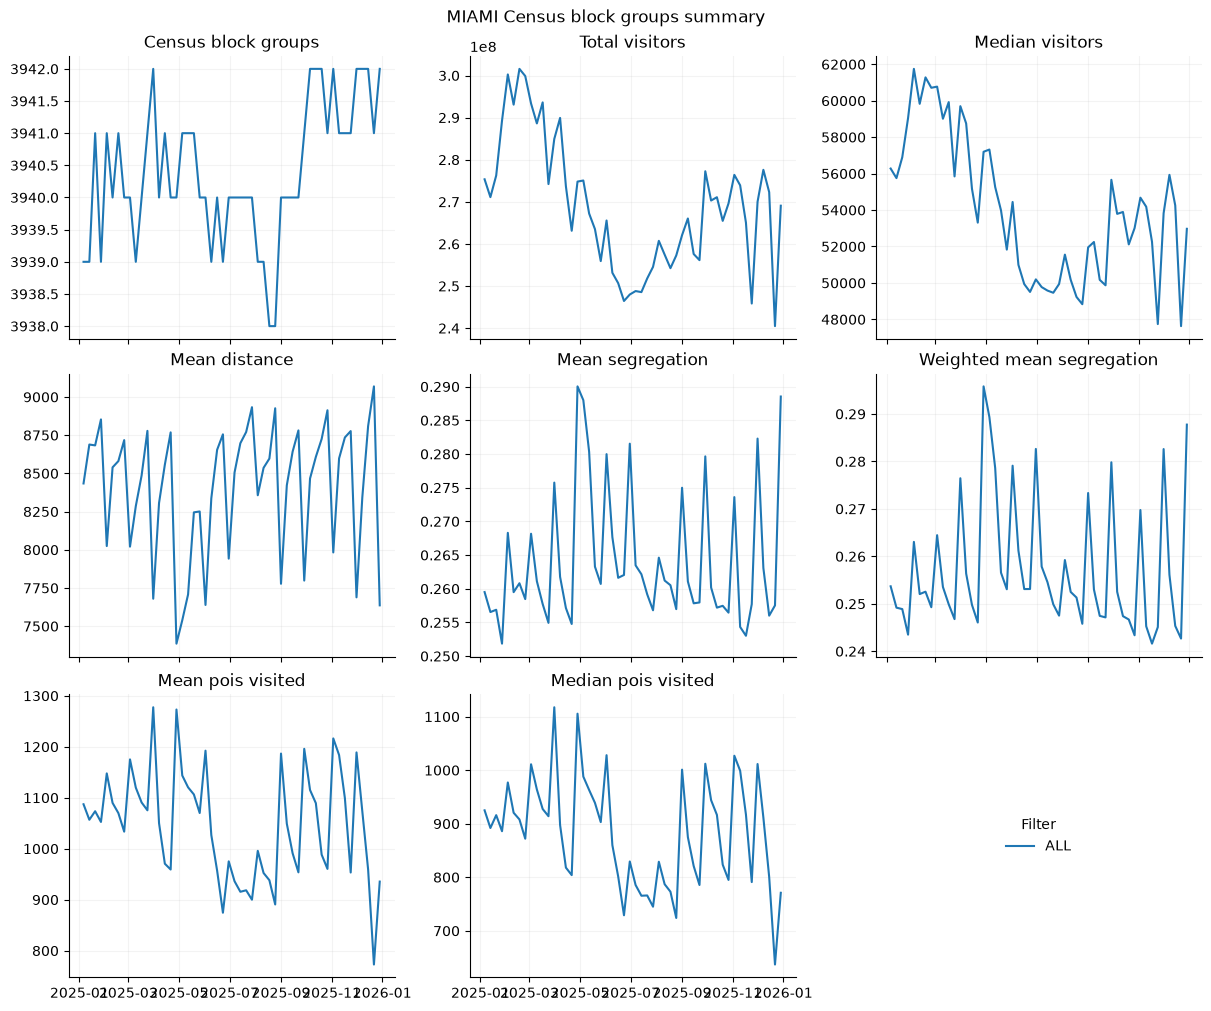

In [8]:
agg = (
    cbg_visits_weekly
    .group_by("DATE_RANGE_START")
    .agg(
        pl.col("GEOID").n_unique().alias("NUM_CBGS"),
        pl.col("TOTAL_VISITORS").sum().alias("TOTAL_VISITORS"),
        pl.col("TOTAL_VISITORS").median().alias("MEDIAN_VISITORS"),
        pl.col("AVG_DIST").mean().alias("MEAN_DIST"),
        pl.col("SEGREGATION").mean().alias("MEAN_SEGREGATION"),
        ((pl.col("SEGREGATION") * pl.col("TOTAL_VISITORS")).sum() / pl.col("TOTAL_VISITORS").sum()).alias("W_MEAN_SEGREGATION"),
        pl.col("NUM_POIS").mean().alias("MEAN_NUM_POIS"),
        pl.col("NUM_POIS").median().alias("MEDIAN_NUM_POIS"),
        pl.col("NUM_POIS").quantile(.25).alias("Q25_NUM_POIS"),
        pl.col("NUM_POIS").quantile(.75).alias("Q75_NUM_POIS"),
    )
    .sort("DATE_RANGE_START")
)

fig, axes = plt.subplots(
    3,
    3,
    figsize=(12, 10),
    sharex=True,
    constrained_layout=True,
)
plot_cbgs(agg, "ALL", axes)

# Legend in the next free axis
n_plots = 8
free_ax = axes.flat[n_plots]
free_ax.set_visible(True)
free_ax.axis("off")

handles, labels = axes.flat[0].get_legend_handles_labels()
free_ax.legend(handles, labels, loc="center", title="Filter", frameon=False)
fig.suptitle("MIAMI Census block groups summary")
fig.savefig("cbgs.png", dpi=200)

In [4]:
with db.get_con() as con:
    tracts = con.sql("""
        SELECT ID_STORE, DATE_RANGE_START, SUM(VISITOR_COUNTS) AS TOTAL_VISITORS, COUNT(DISTINCT HOME_CENSUS_TRACT) AS NUM_TRACTS
        FROM census_tract_visits
        GROUP BY ID_STORE, DATE_RANGE_START
    """).pl()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

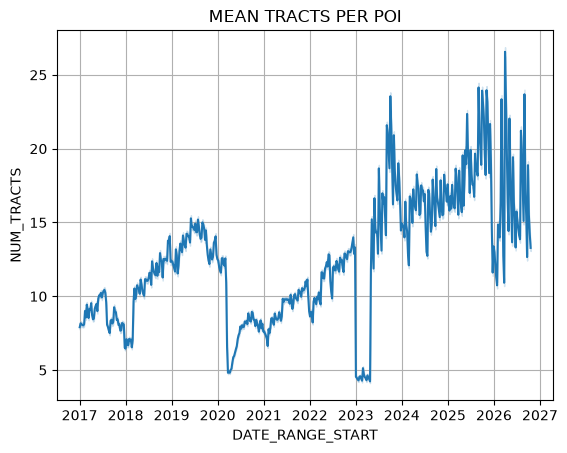

In [5]:
ax = sns.lineplot(tracts.to_pandas(), x="DATE_RANGE_START", y="NUM_TRACTS")
ax.set_title("MEAN TRACTS PER POI")
ax.grid()

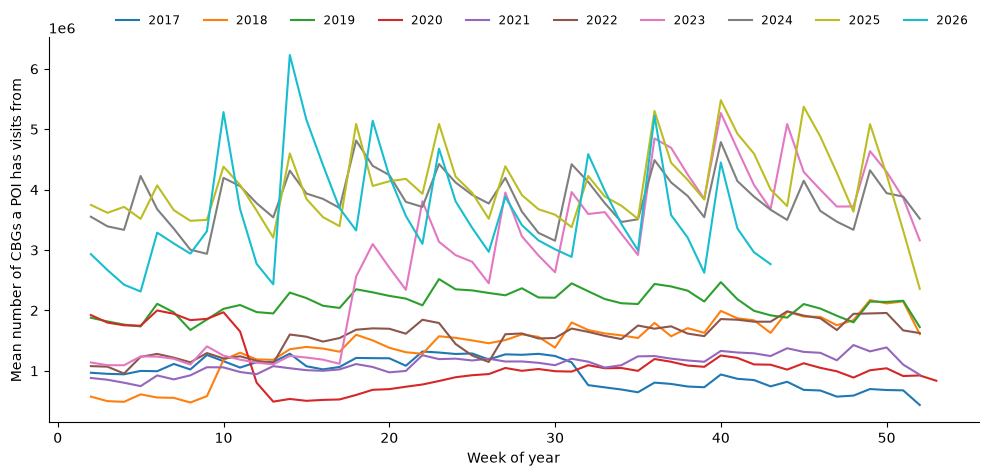

In [5]:
fig, ax = plt.subplots(figsize=(12, 5))

agg = (
    pois_weekly
    .group_by("DATE_RANGE_START")
    .agg(pl.col("NUM_HOME_GROUPS").sum())
    .sort("DATE_RANGE_START")
    .with_columns(pl.col("DATE_RANGE_START").dt.week().alias("week"))
)

years = list(range(2017, 2027))
colors = sns.color_palette("tab10", n_colors=len(years))
for year, color in zip(years, colors):
    X = agg.filter(pl.col("DATE_RANGE_START").dt.year() == year, pl.col("week") > pl.col("week").shift(1))
    ax.plot(X["week"], X["NUM_HOME_GROUPS"], label=str(year), color=color)

ax.set_xlabel("Week of year")
ax.set_ylabel("Mean number of CBGs a POI has visits from")
ax.legend(ncols=len(years), bbox_to_anchor=(1, 1),
              loc='lower right', fontsize='small', frameon=False)
sns.despine()

Text(0, 0.5, 'Mean number of CBGs a POI has visits from')

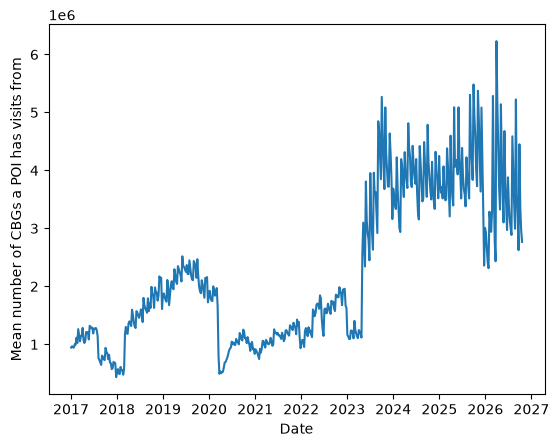

In [6]:
fig, ax = plt.subplots()
ax.plot(agg["DATE_RANGE_START"], agg["NUM_HOME_GROUPS"])
ax.set_xlabel("Date")
ax.set_ylabel("Mean number of CBGs a POI has visits from")

In [ ]:
fig, ax = plt.subplots()
ax.plot(agg["DATE_RANGE_START"], agg["NUM_HOME_GROUPS"])
ax.set_xlabel("Date")
ax.set_ylabel("Mean number of CBGs a POI has visits from")

In [ ]:
sns.boxplot(
    pois_weekly.to_pandas(),
    x=pois_weekly["DATE_RANGE_START"].dt.year(),
    y="NUM_HOME_GROUPS"
)

In [29]:
dtype = pl.Struct({
    "<5": pl.Int64,
    "5-20": pl.Int64,
    "21-60": pl.Int64,
    "61-240": pl.Int64,
    ">240": pl.Int64,
})
with db.get_con() as con:
    dwell = con.sql("""
        SELECT DATE_RANGE_START, ID_STORE, MEDIAN_DWELL, BUCKETED_DWELL_TIMES
        FROM read_parquet('../data/ny-weekly-patterns-plus/*.parquet')
    """).pl().with_columns(pl.col("BUCKETED_DWELL_TIMES").str.json_decode(dtype))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[Text(0.5, 0, 'Date'),
 Text(0, 0.5, 'Mean Median Dwell'),
 Text(0.5, 1.0, 'Mean Median Dwell over time')]

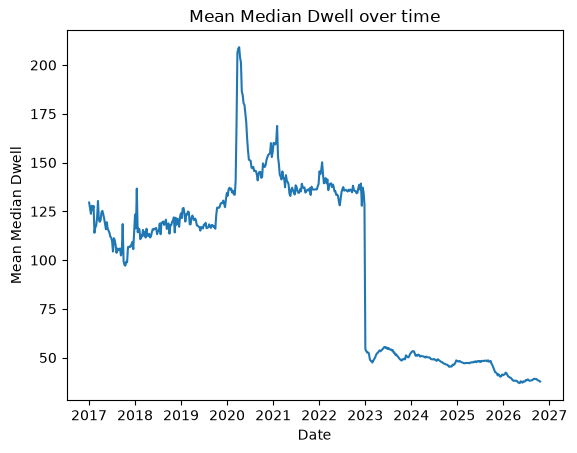

In [20]:
agg = dwell.group_by("DATE_RANGE_START").agg(
    pl.col("MEDIAN_DWELL").mean()
).sort("DATE_RANGE_START")
fig, ax = plt.subplots()
ax.plot(agg["DATE_RANGE_START"], agg["MEDIAN_DWELL"])
ax.set(
    xlabel="Date",
    ylabel="Mean Median Dwell",
    title="Mean Median Dwell over time"
)

In [41]:
agg_b

DATE_RANGE_START,<5,5-20,21-60,61-240,>240
datetime[μs],i64,i64,i64,i64,i64
2017-01-02 00:00:00,366446257,32304811,28423727,29867344,39786414
2017-01-09 00:00:00,395401062,32385077,28965980,32292821,43108753
2017-01-16 00:00:00,395172237,32567085,29086774,32007203,42555249
2017-01-23 00:00:00,404895411,31907632,28593110,32771990,45624367
2017-01-30 00:00:00,388017069,32505532,28090836,31412408,43066532
…,…,…,…,…,…
2026-09-21 00:00:00,456327312,41104836,28307744,29934329,30041718
2026-09-28 00:00:00,459617484,41289292,28321591,29818516,29779678
2026-10-05 00:00:00,468661202,41684314,28585707,30251452,30114585


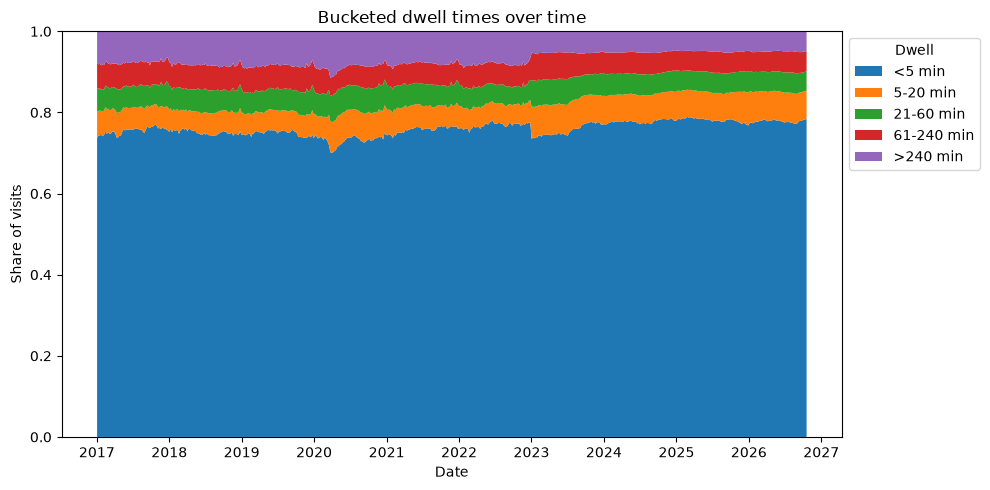

In [39]:
buckets = ["<5", "5-20", "21-60", "61-240", ">240"]

agg_b = (
    dwell
    .unnest("BUCKETED_DWELL_TIMES")
    .group_by("DATE_RANGE_START")
    .agg([pl.col(b).sum() for b in buckets])
    .sort("DATE_RANGE_START")
)

# Share of visits per bucket
agg_share = agg_b.with_columns(
    total=pl.sum_horizontal(buckets)
).with_columns(
    [(pl.col(b) / pl.col("total")).alias(b) for b in buckets]
)

fig, ax = plt.subplots(figsize=(10, 5))
ax.stackplot(
    agg_share["DATE_RANGE_START"],
    [agg_share[b] for b in buckets],
    labels=[f"{b} min" for b in buckets],
)
ax.set(
    xlabel="Date",
    ylabel="Share of visits",
    title="Bucketed dwell times over time",
    ylim=(0, 1),
)
ax.legend(loc="upper left", bbox_to_anchor=(1, 1), title="Dwell")
fig.tight_layout()

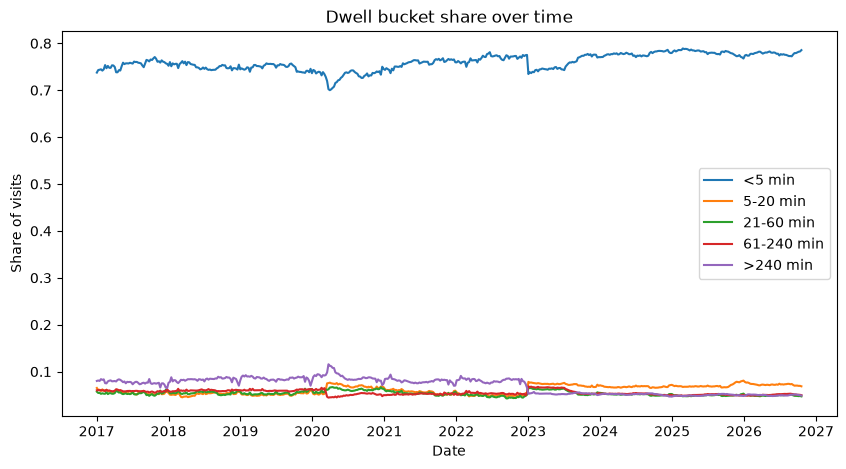

In [40]:
fig, ax = plt.subplots(figsize=(10, 5))
for b in buckets:
    ax.plot(agg_share["DATE_RANGE_START"], agg_share[b], label=f"{b} min")
ax.set(xlabel="Date", ylabel="Share of visits", title="Dwell bucket share over time")
ax.legend()